# Image Viewer 2 — Parquet と画像ディレクトリを別指定するビューワー

`score_images.py --output-dir` で出力したスコア parquet と、元の `images/` ディレクトリを
それぞれ独立して指定できる。

- スコア分布（ヒストグラム・箱ひげ図）
- 文字ごとグリッド表示
- Top-N / Bottom-N ランキング表示

In [12]:
from pathlib import Path
import yaml
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import numpy as np

# ============================================================
# パス設定（すべてここで完結）
# ============================================================
# スコア parquet のパス（score_images.py --output-dir の出力ファイル）
PARQUET_PATH = Path("results/scores/2026-05-22_scorer_H/font2dataset_ascii_google_scores.parquet")

# 画像ディレクトリ（parquet の 'file' 列の親ディレクトリ）
IMAGES_DIR = Path("data/datasets/font2dataset_ascii_google/images")

# スプリットファイル（None で全データ表示）
SPLIT_FILE = Path("data/datasets/font2dataset_ascii_google/split_ascii_seed42.yaml")
SPLIT = "train"   # "train" / "val" / "test" / "all"

# 複数 Parquet 比較セル用データセット定義
SCORES_ROOT = Path("results/scores/2026-05-22_scorer_H")
COMPARE_DATASETS: dict[str, tuple[Path, Path]] = {
    "Real (google)": (
        SCORES_ROOT / "font2dataset_ascii_google_scores.parquet",
        Path("data/datasets/font2dataset_ascii_google/images"),
    ),
    "Generated (diffusion_H)": (
        SCORES_ROOT / "last_scores.parquet",
        Path("results/2026-05-20_diffusion_H/checkpoints/last/images"),
    ),
}

# ============================================================
# 表示設定
# ============================================================
FILTER_CHARS  = list("H")  # 表示する文字（空リストで全文字）
FILTER_FAMILY = ""       # フォントファミリー名の部分一致フィルタ（空文字で全て）
MAX_PER_CHAR  = 20       # 文字ごとグリッドの最大表示枚数
COLS          = 10       # グリッドの列数
IMG_SIZE      = 1.2      # 1セルのインチサイズ
# ============================================================

meta = pd.read_parquet(PARQUET_PATH)

# スプリットフィルタ（font_family 列でフィルタリング）
split_families: set[str] | None = None
if SPLIT_FILE is not None and SPLIT_FILE.exists() and SPLIT != "all":
    with open(SPLIT_FILE) as f:
        split_cfg = yaml.safe_load(f)
    split_families = set(split_cfg["families"][SPLIT])
    meta = meta[meta["font_family"].isin(split_families)]

print(f"Parquet    : {PARQUET_PATH.name}")
print(f"Images dir : {IMAGES_DIR}")
print(f"Split      : {SPLIT}  ({f'{len(split_families)} families' if split_families else 'all families'})")
print(f"Total rows : {len(meta):,}")
if "char" in meta.columns:
    print(f"Chars      : {sorted(meta['char'].unique())}")
if "font_family" in meta.columns:
    print(f"Families   : {meta['font_family'].nunique()} families")
if "realness_score" in meta.columns and meta["realness_score"].notna().any():
    s = meta["realness_score"]
    print(f"Score      : mean={s.mean():.4f}  std={s.std():.4f}  min={s.min():.4f}  max={s.max():.4f}")
meta.head(3)

Parquet    : font2dataset_ascii_google_scores.parquet
Images dir : data/datasets/font2dataset_ascii_google/images
Split      : train  (all families)
Total rows : 358,368
Chars      : [' ', '!', '"', '#', '$', '%', '&', "'", '(', ')', '*', '+', ',', '-', '.', '/', '0', '1', '2', '3', '4', '5', '6', '7', '8', '9', ':', ';', '<', '=', '>', '?', '@', 'A', 'B', 'C', 'D', 'E', 'F', 'G', 'H', 'I', 'J', 'K', 'L', 'M', 'N', 'O', 'P', 'Q', 'R', 'S', 'T', 'U', 'V', 'W', 'X', 'Y', 'Z', '[', '\\', ']', '^', '_', '`', 'a', 'b', 'c', 'd', 'e', 'f', 'g', 'h', 'i', 'j', 'k', 'l', 'm', 'n', 'o', 'p', 'q', 'r', 's', 't', 'u', 'v', 'w', 'x', 'y', 'z', '{', '|', '}', '~']
Families   : 2794 families
Score      : mean=0.9593  std=0.0555  min=0.0877  max=0.9992


,file,char,unicode,codepoint,font_path,font_family,font_style,realness_score
0,0020_42dotSans[wght]_000.png,,U+0020,32,data/datasets/external/google_fonts...,42dot Sans Light,Regular,0.974375
1,0020_ADLaMDisplay-Regular_000.png,,U+0020,32,data/datasets/external/google_fonts...,ADLaM Display,Regular,0.974375
2,0020_ABeeZee-Regular_000.png,,U+0020,32,data/datasets/external/google_fonts...,ABeeZee,Regular,0.974375


## Realness Score 分布

Char filter: ['H']  →  3,754 rows


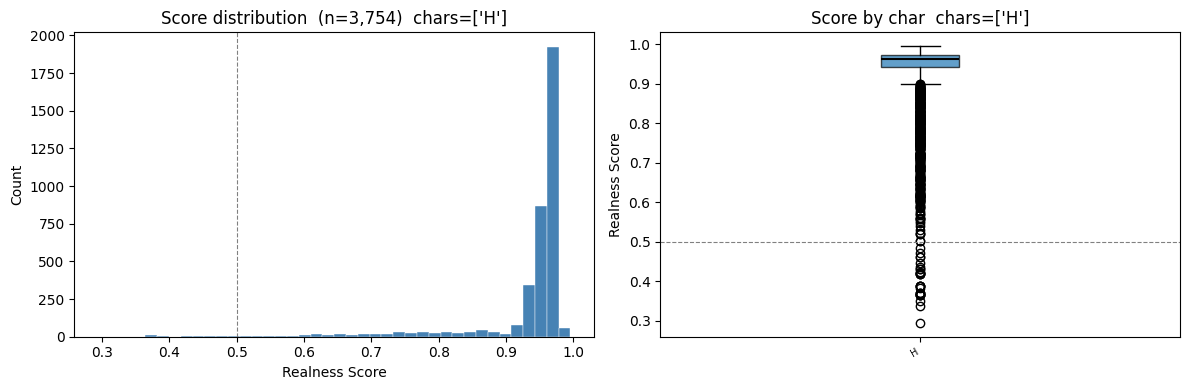

,n,mean,std,min,max
char,,,,,
H,3754,0.9335,0.0877,0.2943,0.9956


In [13]:
# グループ化する列（存在する列のみ有効）
GROUP_BY = "char"   # "char" / "font_family" / "cond_scale" / "font_style" など
DIST_FILTER_CHARS = list("H")  # 表示する文字（空リストで全文字）例: list("AHZ")
if "realness_score" not in meta.columns or meta["realness_score"].isna().all():
    print("realness_score 列がありません。score_images.py を先に実行してください。")
else:
    view = meta.dropna(subset=["realness_score"]).copy()
    if DIST_FILTER_CHARS and "char" in view.columns:
        view = view[view["char"].isin(DIST_FILTER_CHARS)]
        print(f"Char filter: {DIST_FILTER_CHARS}  →  {len(view):,} rows")

    fig, axes = plt.subplots(1, 2, figsize=(12, 4))

    # ヒストグラム（全体）
    axes[0].hist(view["realness_score"], bins=40, color="steelblue",
                 edgecolor="white", linewidth=0.3)
    axes[0].axvline(0.5, color="gray", linestyle="--", linewidth=0.8)
    axes[0].set_xlabel("Realness Score")
    axes[0].set_ylabel("Count")
    char_info = f"  chars={DIST_FILTER_CHARS}" if DIST_FILTER_CHARS else ""
    axes[0].set_title(f"Score distribution  (n={len(view):,}){char_info}")

    # グループ別箱ひげ図
    if GROUP_BY in view.columns:
        groups = sorted(view[GROUP_BY].unique())
        data = [view.loc[view[GROUP_BY] == g, "realness_score"].values for g in groups]
        bp = axes[1].boxplot(data, patch_artist=True,
                              medianprops=dict(color="black", linewidth=1.5))
        colors = plt.cm.tab10(np.linspace(0, 1, len(groups)))
        for patch, color in zip(bp["boxes"], colors):
            patch.set_facecolor(color)
            patch.set_alpha(0.7)
        axes[1].set_xticks(range(1, len(groups) + 1))
        axes[1].set_xticklabels(groups, rotation=30, ha="right", fontsize=7)
        axes[1].axhline(0.5, color="gray", linestyle="--", linewidth=0.8)
        axes[1].set_ylabel("Realness Score")
        axes[1].set_title(f"Score by {GROUP_BY}{char_info}")
    else:
        axes[1].axis("off")
        axes[1].text(0.5, 0.5, f"'{GROUP_BY}' 列なし", ha="center", va="center")

    fig.tight_layout()
    plt.show()

    # 数値サマリ
    if GROUP_BY in view.columns:
        summary = view.groupby(GROUP_BY)["realness_score"].agg(["count", "mean", "std", "min", "max"])
        summary.columns = ["n", "mean", "std", "min", "max"]
        display(summary.round(4))

## 文字ごとにグリッド表示

Filtered : 3,754 rows
Chars    : 1
Score    : mean=0.9335  std=0.0877  min=0.2943  max=0.9956


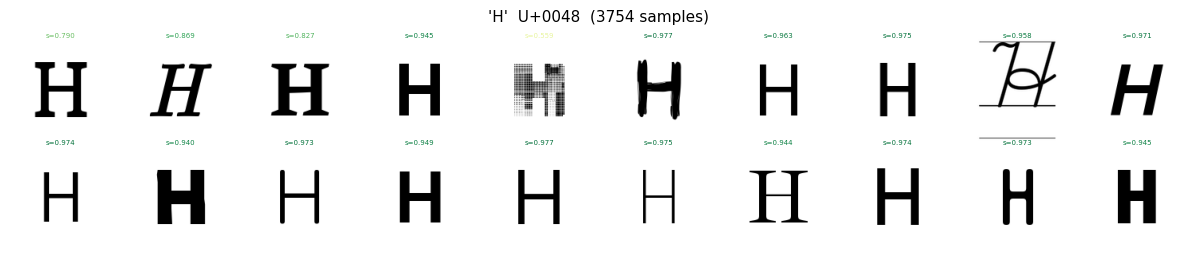

In [14]:
def show_grid(df: pd.DataFrame, title: str, images_dir: Path,
              max_images: int = 20, cols: int = 10, img_size: float = 1.2) -> None:
    """メタデータの行群をグリッド表示する。realness_score 列があれば各画像に表示。"""
    has_score = "realness_score" in df.columns and df["realness_score"].notna().any()
    rows_sample = df.sample(min(max_images, len(df)), random_state=0)
    n = len(rows_sample)
    if n == 0:
        return
    nrows = (n + cols - 1) // cols
    fig, axes = plt.subplots(nrows, cols, figsize=(cols * img_size, nrows * img_size))
    axes = np.array(axes).reshape(-1)
    for ax, (_, row) in zip(axes, rows_sample.iterrows()):
        path = images_dir / row["file"]
        if path.exists():
            ax.imshow(mpimg.imread(str(path)), cmap="gray")
        else:
            ax.text(0.5, 0.5, "N/A", ha="center", va="center", fontsize=6)
        if has_score and pd.notna(row.get("realness_score")):
            label = f"s={row['realness_score']:.3f}"
            color = plt.cm.RdYlGn(float(row["realness_score"]))
            ax.set_title(label, fontsize=5, pad=1, color=color)
        else:
            label = str(row.get("font_style", row.get("font_family", "")))[:12]
            ax.set_title(label, fontsize=5, pad=1)
        ax.axis("off")
    for ax in axes[n:]:
        ax.axis("off")
    fig.suptitle(title, fontsize=11, y=1.01)
    fig.tight_layout(pad=0.3)
    plt.show()


view = meta.copy()
if FILTER_CHARS and "char" in view.columns:
    view = view[view["char"].isin(FILTER_CHARS)]
if FILTER_FAMILY and "font_family" in view.columns:
    view = view[view["font_family"].str.contains(FILTER_FAMILY, case=False, na=False)]

print(f"Filtered : {len(view):,} rows")
if "char" in view.columns:
    print(f"Chars    : {view['char'].nunique()}")
if "realness_score" in view.columns:
    s = view["realness_score"]
    print(f"Score    : mean={s.mean():.4f}  std={s.std():.4f}  min={s.min():.4f}  max={s.max():.4f}")

if "char" in view.columns:
    for char, group in view.groupby("char", sort=True):
        cp = ord(char)
        show_grid(
            group,
            title=f"'{char}'  U+{cp:04X}  ({len(group)} samples)",
            images_dir=IMAGES_DIR,
            max_images=MAX_PER_CHAR,
            cols=COLS,
            img_size=IMG_SIZE,
        )
else:
    show_grid(view, title=f"All images ({len(view)} samples)",
              images_dir=IMAGES_DIR, max_images=MAX_PER_CHAR, cols=COLS, img_size=IMG_SIZE)

## Score Top-N / Bottom-N

Realness Score が高い画像・低い画像をランキング表示する。

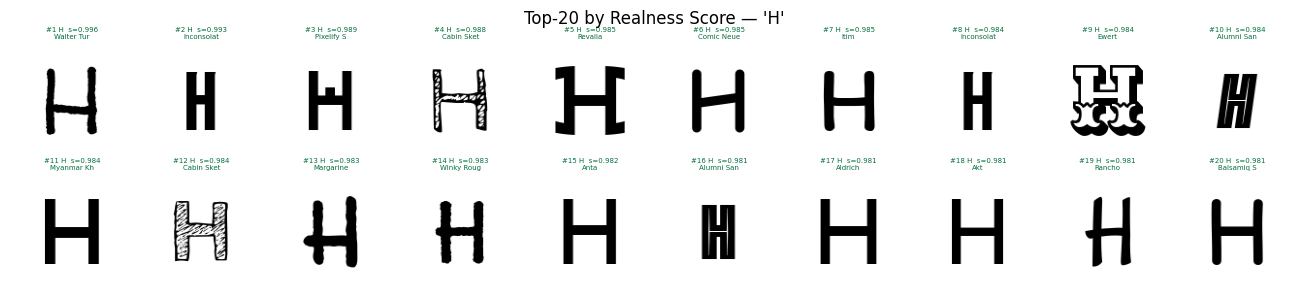

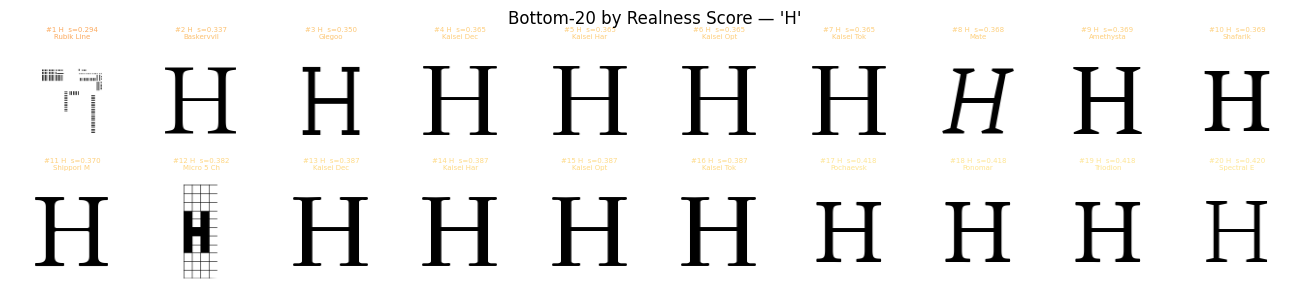

In [15]:
TOPN_N           = 20    # 上位・下位それぞれ何枚表示するか
TOPN_COLS        = 10    # グリッドの列数
TOPN_FILTER_CHAR = "H"   # 特定の文字に絞る場合は "H" など（空文字で全文字）

if "realness_score" not in meta.columns or meta["realness_score"].isna().all():
    print("realness_score 列がありません。score_images.py を先に実行してください。")
else:
    topn_meta = meta.dropna(subset=["realness_score"]).copy()
    if TOPN_FILTER_CHAR and "char" in topn_meta.columns:
        topn_meta = topn_meta[topn_meta["char"] == TOPN_FILTER_CHAR]

    def show_ranked(df: pd.DataFrame, images_dir: Path, n: int, cols: int, high: bool) -> None:
        ranked = df.nlargest(n, "realness_score") if high else df.nsmallest(n, "realness_score")
        label = "Top" if high else "Bottom"
        nrows = (len(ranked) + cols - 1) // cols
        fig, axes = plt.subplots(nrows, cols, figsize=(cols * 1.3, nrows * 1.5))
        axes = np.array(axes).reshape(-1)
        for rank, (ax, (_, row)) in enumerate(zip(axes, ranked.iterrows()), start=1):
            path = images_dir / row["file"]
            if path.exists():
                ax.imshow(mpimg.imread(str(path)), cmap="gray")
            else:
                ax.text(0.5, 0.5, "N/A", ha="center", va="center", fontsize=6)
            score = row["realness_score"]
            char  = row.get("char", "") if "char" in row.index else ""
            style = str(row.get("font_family", ""))[:10]
            ax.set_title(
                f"#{rank} {char}  s={score:.3f}\n{style}",
                fontsize=5, pad=1,
                color=plt.cm.RdYlGn(float(score)),
            )
            ax.axis("off")
        for ax in axes[len(ranked):]:
            ax.axis("off")
        char_info = f" — '{TOPN_FILTER_CHAR}'" if TOPN_FILTER_CHAR else ""
        fig.suptitle(f"{label}-{n} by Realness Score{char_info}", fontsize=12)
        fig.tight_layout(pad=0.4)
        plt.show()

    show_ranked(topn_meta, IMAGES_DIR, n=TOPN_N, cols=TOPN_COLS, high=True)
    show_ranked(topn_meta, IMAGES_DIR, n=TOPN_N, cols=TOPN_COLS, high=False)

## 複数 Parquet の比較

実フォントと生成フォントのスコア parquet を並べて比較する。

Real (google): n=358,368  mean=0.9593  std=0.0555  min=0.0877  max=0.9992
Generated (diffusion_H): n=2,631  mean=0.8693  std=0.2243  min=0.0854  max=0.9999


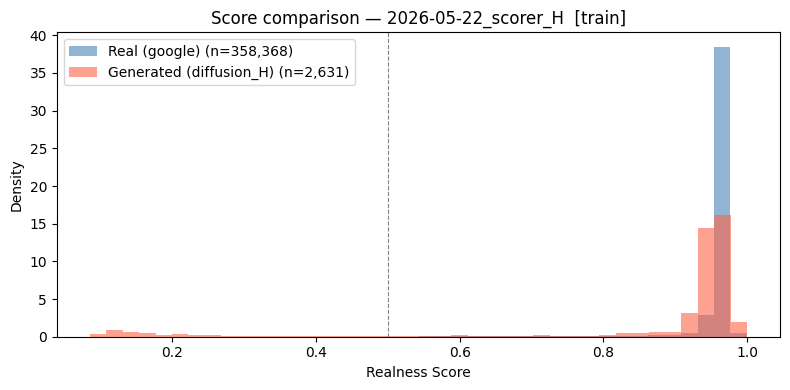

In [16]:
loaded: dict[str, pd.DataFrame] = {}
for name, (parquet_path, images_dir) in COMPARE_DATASETS.items():
    if parquet_path.exists():
        df = pd.read_parquet(parquet_path)
        if split_families is not None and "font_family" in df.columns:
            df = df[df["font_family"].isin(split_families)]
        df["_images_dir"] = str(images_dir)
        loaded[name] = df
        s = df["realness_score"]
        print(f"{name}: n={len(df):,}  mean={s.mean():.4f}  std={s.std():.4f}  "
              f"min={s.min():.4f}  max={s.max():.4f}")
    else:
        print(f"[SKIP] not found: {parquet_path}")

if loaded:
    split_info = f"  [{SPLIT}]" if SPLIT != "all" else ""
    fig, ax = plt.subplots(figsize=(8, 4))
    colors = ["steelblue", "tomato", "forestgreen", "darkorange"]
    for (name, df), color in zip(loaded.items(), colors):
        ax.hist(df["realness_score"], bins=40, alpha=0.6, color=color,
                label=f"{name} (n={len(df):,})", density=True)
    ax.axvline(0.5, color="gray", linestyle="--", linewidth=0.8)
    ax.set_xlabel("Realness Score")
    ax.set_ylabel("Density")
    ax.set_title(f"Score comparison — {SCORES_ROOT.name}{split_info}")
    ax.legend()
    fig.tight_layout()
    plt.show()